# BUSI2066 Assignment 2

10% of the course grade | 100 marks

## Compare two service desk replies

A service desk tried Standard and Checklist replies. Help its manager compare
resolution rates and staff handling time, then predict time for similar requests.
The questions tell you which tests and models to use.

The data in `service_requests.csv` are **made up for this assignment**.
Each row is a different service request. No customer appears twice.
The file has no missing values. Replies were not assigned at random.
These results show associations, not proof that a reply causes a change.

| Column | Meaning |
| --- | --- |
| request_id | Request label. Do not use it as a predictor |
| reply | Standard or Checklist reply |
| team | North, Central or South service team |
| items | Number of items the request concerns |
| handling_min | Total staff handling time in minutes |
| resolved | 1 if resolved within 48 hours; 0 otherwise |

## Instructions

* Put the CSV beside this notebook and run the setup cells. They load the data as `d`.
* Complete the code in each question. Show the requested tables, numbers and charts.
* Each question has one short written answer. One sentence is enough.
  You do not need to write hypotheses or explain why a test was chosen.
* Use the 5% significance level and two sided tests. Assume independent requests
  and a stable process for the tests. These are modelling assumptions.
* Show minutes to 2 decimal places and rates, statistics and coefficients to
  4 decimal places. Use scientific notation for very small p values.
  Round only the final results. These are reporting choices for this assignment.
* AI may help with code. Run it and check its results. Write your own short answers.
* Run all cells and save the notebook with its outputs and charts. Upload the
  completed `.ipynb` to Moodle by its displayed deadline. The Moodle activity
  gives the applicable late submission policy. Check that you uploaded the correct file.

The setup makes Standard the reference reply and North the reference team.
Use these reference groups in Question 4.


In [8]:
%pip install -q pandas matplotlib seaborn scipy statsmodels


[notice] A new release of pip is available: 26.2.2 -> 26.3
[notice] To update, run: python -m pip install --upgrade pip
Note: you may need to restart the kernel to use updated packages.


In [9]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.stats import chi2_contingency, ttest_ind
from statsmodels.formula.api import ols

d = pd.read_csv('service_requests.csv')
d['reply'] = pd.Categorical(d['reply'], categories=['Standard', 'Checklist'])
d['team'] = pd.Categorical(d['team'], categories=['North', 'Central', 'South'])
d.head()

,request_id,reply,team,items,handling_min,resolved
0,233,Checklist,North,6,5.46,1
1,53,Standard,North,7,8.75,1
2,1,Standard,North,3,5.59,1
3,95,Standard,Central,1,5.44,0
4,174,Checklist,South,5,8.89,1


## 1. Run the association test (25 marks)

Use `pd.crosstab` and `chi2_contingency` to compare reply and resolution.

1. Make and display a table of **counts** for `reply` and `resolved`.
   Use the original request rows. **(7 marks)**
2. Pass that table to `chi2_contingency`. Display the chi square statistic,
   p value and smallest expected count. Use the function's default settings. **(9 marks)**
3. Display the resolution rate for each reply. You can use
   `d.groupby('reply')['resolved'].mean()`. **(7 marks)**
4. In one sentence, does your p value show evidence of an association at 5%? **(2 marks)**

In [10]:
# 1. Association between reply and resolution
resolution_counts = pd.crosstab(d['reply'], d['resolved'])
display(resolution_counts)

chi_square, p_value, degrees_of_freedom, expected_counts = chi2_contingency(resolution_counts)
print(f"Chi square statistic: {chi_square:.4f}")
print(f"p value: {p_value:.4e}")
print(f"Smallest expected count: {expected_counts.min():.4f}")

resolution_rates = d.groupby('reply', observed=False)['resolved'].mean()
print("Resolution rates:")
for reply, rate in resolution_rates.items():
    print(f"{reply}: {rate:.4f}")

resolved,0,1
reply,,
Standard,35,85
Checklist,9,111


Chi square statistic: 17.3933
p value: 3.0389e-05
Smallest expected count: 22.0000
Resolution rates:
Standard: 0.7083
Checklist: 0.9250


Yes, the p value is below 0.05, so the sample provides evidence of an association between reply and resolution.

## 2. Compare handling time (25 marks)

Use Welch's two sample t test to compare handling time.

1. Use `d.loc` to select the `handling_min` values for each reply into
   `checklist_time` and `standard_time`. Display both sample means. **(8 marks)**
2. Run Welch's test using the two groups above. Pass the Checklist handling
   times as the first input and the Standard handling times as the second.
   Display t and p. You do not need a confidence interval. **(8 marks)**
3. Draw a box plot of `handling_min` by `reply`. Give it a title and
   label the axes. **(7 marks)**
4. In one sentence, which reply has the higher sample mean handling time? **(2 marks)**

Checklist mean: 9.21 minutes
Standard mean: 7.71 minutes
Welch t statistic: 4.7368
p value: 3.7409e-06


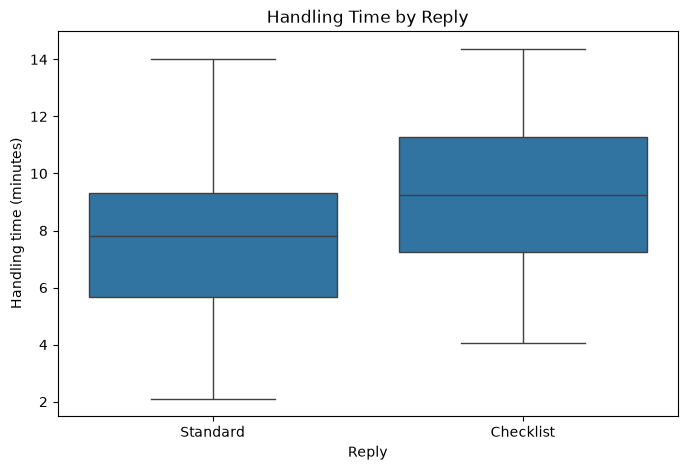

In [11]:
# 2. Compare handling time
checklist_time = d.loc[d['reply'] == 'Checklist', 'handling_min']
standard_time = d.loc[d['reply'] == 'Standard', 'handling_min']

print(f"Checklist mean: {checklist_time.mean():.2f} minutes")
print(f"Standard mean: {standard_time.mean():.2f} minutes")

t_statistic, t_p_value = ttest_ind(checklist_time, standard_time, equal_var=False)
print(f"Welch t statistic: {t_statistic:.4f}")
print(f"p value: {t_p_value:.4e}")

plt.figure(figsize=(8, 5))
sns.boxplot(data=d, x='reply', y='handling_min')
plt.title('Handling Time by Reply')
plt.xlabel('Reply')
plt.ylabel('Handling time (minutes)')
plt.show()

Checklist has the higher sample mean handling time (9.21 minutes versus 7.71 minutes).

## 3. Fit a model using request size (25 marks)

Use `ols('handling_min ~ items', data=d).fit()` and call the
fitted model `size_model`.

1. Fit the model. Display its coefficients using `.params` and its
   R squared using `.rsquared`. **(8 marks)**
2. Select request 233 using `d.loc`. Use `.predict()` to find its fitted
   handling time. Display its actual time, fitted time and residual.
   Calculate residual as **actual minus fitted**. **(8 marks)**
3. Draw a scatter plot with `items` on the horizontal axis and `handling_min`
   on the vertical axis. Give it a title and label the axes. **(6 marks)**
4. In one sentence, what does this request's residual sign tell you about
   its actual time compared with its fitted time? **(3 marks)**

Coefficients:
Intercept: 4.6967
items: 0.6209
R squared: 0.5663
Request 233 actual time: 5.46 minutes
Request 233 fitted time: 8.42 minutes
Request 233 residual: -2.96 minutes


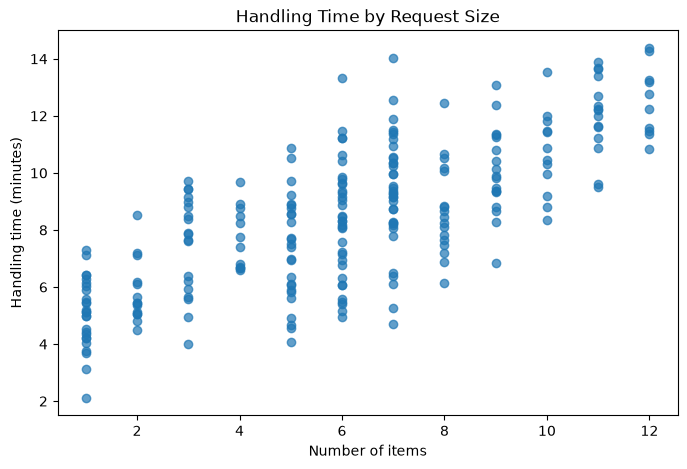

In [12]:
# 3. Model handling time using request size
size_model = ols('handling_min ~ items', data=d).fit()

print("Coefficients:")
for name, value in size_model.params.items():
    print(f"{name}: {value:.4f}")
print(f"R squared: {size_model.rsquared:.4f}")

request_233 = d.loc[d['request_id'] == 233]
actual_233 = request_233['handling_min'].iloc[0]
fitted_233 = size_model.predict(request_233[['items']]).iloc[0]
residual_233 = actual_233 - fitted_233

print(f"Request 233 actual time: {actual_233:.2f} minutes")
print(f"Request 233 fitted time: {fitted_233:.2f} minutes")
print(f"Request 233 residual: {residual_233:.2f} minutes")

plt.figure(figsize=(8, 5))
plt.scatter(d['items'], d['handling_min'], alpha=0.7)
plt.title('Handling Time by Request Size')
plt.xlabel('Number of items')
plt.ylabel('Handling time (minutes)')
plt.show()

The negative residual means that request 233's actual handling time was below its fitted handling time.

## 4. Add reply and team to the model (25 marks)

Use `ols('handling_min ~ items + reply + team', data=d).fit()`.
Call this model `full_model`. The supplied table below contains two made up
requests with **6 items, both handled by North**. Only the reply differs.

1. Fit the model. Display all its coefficients and R squared. **(8 marks)**
2. Use `full_model.predict(new_requests)` to predict handling time for both
   supplied requests. Display each reply beside its prediction. **(8 marks)**
3. Use code to display **Checklist prediction minus Standard prediction**.
   This is the fitted time difference for the two requests. **(6 marks)**
4. Interpret the Checklist coefficient in one sentence. Name the reference
   reply and say which other variables are held fixed. **(3 marks)**

You do not need to compare models with ANOVA or explain why the raw group
means and the regression coefficient can point in different directions.

In [13]:
new_requests = pd.DataFrame({
    'items': [6, 6],
    'reply': ['Standard', 'Checklist'],
    'team': ['North', 'North']
})
new_requests

,items,reply,team
0,6,Standard,North
1,6,Checklist,North


In [14]:
# 4. Full model with reply and team
full_model = ols('handling_min ~ items + reply + team', data=d).fit()

print("Coefficients:")
for name, value in full_model.params.items():
    print(f"{name}: {value:.4f}")
print(f"R squared: {full_model.rsquared:.4f}")

new_requests = pd.DataFrame({
    'items': [6, 6],
    'reply': ['Standard', 'Checklist'],
    'team': ['North', 'North']
})
new_requests['reply'] = pd.Categorical(new_requests['reply'], categories=['Standard', 'Checklist'])
new_requests['team'] = pd.Categorical(new_requests['team'], categories=['North', 'Central', 'South'])

prediction_values = full_model.predict(new_requests)
predictions = pd.DataFrame({
    'reply': new_requests['reply'],
    'predicted_handling_min': prediction_values
})
display(predictions)

checklist_minus_standard = prediction_values.iloc[1] - prediction_values.iloc[0]
print(f"Checklist prediction minus Standard prediction: {checklist_minus_standard:.2f} minutes")

Coefficients:
Intercept: 3.1843
reply[T.Checklist]: -2.4316
team[T.Central]: 0.9065
team[T.South]: 2.1740
items: 0.8970
R squared: 0.8168


,reply,predicted_handling_min
0,Standard,8.566326
1,Checklist,6.134754


Checklist prediction minus Standard prediction: -2.43 minutes


The Checklist coefficient of -2.4316 means that, relative to Standard and holding items and team fixed, Checklist is associated with 2.4316 fewer minutes of handling time.